# 03 · Sales & product analysis
**Business questions:** revenue trend · category contribution · average order value & skew · geography · order status · purchase timing.

Metric definitions: **item revenue** = Σ price (no freight) · **delivered** = `order_status = 'delivered'` with a delivery date · trends use full months 2017-01 → 2018-08.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
import olist
olist.setup_plots()
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40
BRL = mtick.FuncFormatter(lambda x, p: f"R${x/1e6:.1f}M" if abs(x) >= 1e6 else f"R${x/1e3:.0f}k")

In [2]:
t = olist.load_raw()
f = pd.read_csv(olist.PROCESSED / "order_facts.csv.gz", parse_dates=olist.ORDER_DATE_COLS)
d = f[f.is_delivered].copy()
d["month"] = d.order_purchase_timestamp.dt.to_period("M").dt.to_timestamp()
trend = olist.in_trend_window(d)
print(f"{len(d):,} delivered orders | total item revenue R$ {d.item_revenue.sum():,.0f} | total GMV (incl. freight) R$ {d.total_value.sum():,.0f}")

96,470 delivered orders | total item revenue R$ 13,220,249 | total GMV (incl. freight) R$ 15,418,395


## Chart 1 · Monthly revenue and order volume

Jan-17 -> Jan-18 revenue: 8.3x | orders: 9.4x
Nov-17 revenue vs Oct-17: +52%; Dec-17 vs Nov-17: -26%
H1-2018 vs H1-2017 item revenue: +182%
2018 monthly growth flattening: Mar->Aug 2018 revenue change -12.0%


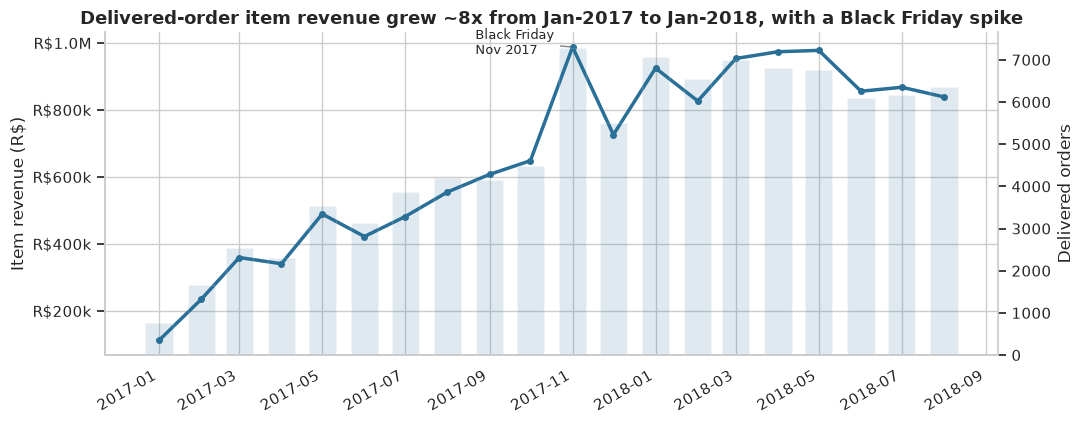

In [3]:
m = trend.groupby("month").agg(item_revenue=("item_revenue","sum"), orders=("order_id","count"), aov=("item_revenue","mean"))
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(m.index, m.item_revenue, color="#2a6f97", lw=2.5, marker="o", ms=4)
ax.set_ylabel("Item revenue (R$)"); ax.yaxis.set_major_formatter(BRL)
ax2 = ax.twinx(); ax2.bar(m.index, m.orders, width=20, color="#2a6f97", alpha=.15); ax2.set_ylabel("Delivered orders"); ax2.grid(False)
ax2.spines["right"].set_visible(True)
nov = m.item_revenue.idxmax() if False else pd.Timestamp("2017-11-01")
ax.annotate("Black Friday\nNov 2017", (nov, m.loc[nov,"item_revenue"]), xytext=(-70, -5), textcoords="offset points", arrowprops=dict(arrowstyle="-", color="gray"), fontsize=9)
ax.set_title("Delivered-order item revenue grew ~8x from Jan-2017 to Jan-2018, with a Black Friday spike")
fig.autofmt_xdate(); plt.tight_layout(); olist.save_fig(fig, "01_monthly_revenue_orders.png")
jan17, jan18 = m.loc["2017-01-01"], m.loc["2018-01-01"]
print(f"Jan-17 -> Jan-18 revenue: {jan18.item_revenue/jan17.item_revenue:.1f}x | orders: {jan18.orders/jan17.orders:.1f}x")
print(f"Nov-17 revenue vs Oct-17: {m.loc['2017-11-01','item_revenue']/m.loc['2017-10-01','item_revenue']-1:+.0%}; Dec-17 vs Nov-17: {m.loc['2017-12-01','item_revenue']/m.loc['2017-11-01','item_revenue']-1:+.0%}")
h1_17 = m.loc["2017-01-01":"2017-06-01"].item_revenue.sum(); h1_18 = m.loc["2018-01-01":"2018-06-01"].item_revenue.sum()
print(f"H1-2018 vs H1-2017 item revenue: {h1_18/h1_17-1:+.0%}")
print(f"2018 monthly growth flattening: Mar->Aug 2018 revenue change {m.loc['2018-08-01','item_revenue']/m.loc['2018-03-01','item_revenue']-1:+.1%}")

**Interpretation.** Revenue ramps up through 2017, peaks at Black Friday (Nov 2017), then plateaus at ~R$0.8–1.0M/month through 2018 — growth shifted from *accelerating* to *flat*. *Hypothesis (not tested here):* the marketplace saturated its acquisition channels in 2018.

## Chart 2 · Order status distribution

Not delivered/canceled (in-flight or unavailable): 2,338 (2.4%)


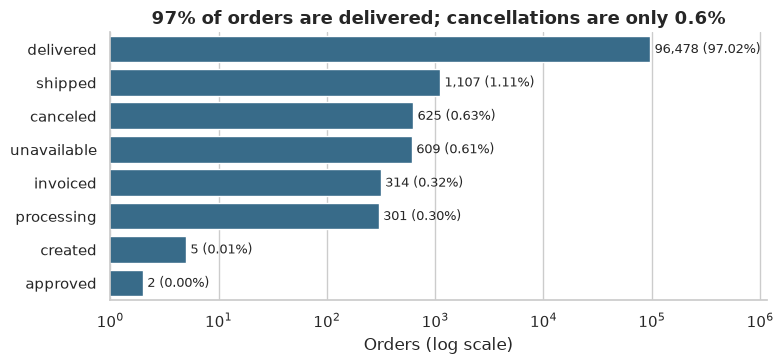

In [4]:
s = f.order_status.value_counts()
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(x=s.values, y=s.index, ax=ax, color="#2a6f97", order=s.index)
ax.set_xscale("log"); ax.set_xlabel("Orders (log scale)"); ax.set_ylabel("")
for i, (v, k) in enumerate(zip(s.values, s.index)): ax.text(v*1.1, i, f"{v:,} ({v/s.sum():.2%})", va="center", fontsize=9)
ax.set_xlim(1, s.max()*12); ax.set_title("97% of orders are delivered; cancellations are only 0.6%")
plt.tight_layout(); olist.save_fig(fig, "02_order_status.png")
not_done = f[~f.order_status.isin(["delivered","canceled"])].shape[0]
print(f"Not delivered/canceled (in-flight or unavailable): {not_done:,} ({not_done/len(f):.1%})")

**Interpretation.** Fulfilment completion is very high. `unavailable` (609) is nearly as large as `canceled` (625) and is a *seller-stock* failure, not a customer choice — a separate lever from cancellations. Most orders with no items (e.g. 603 `unavailable`) never reached shipping.

## Chart 3 · Top categories — revenue and volume

                           revenue  items  avg_price  share
category                                                   
health_beauty         1,233,131.72   9465     130.28   0.09
watches_gifts         1,165,898.98   5857     199.06   0.09
bed_bath_table        1,023,434.76  10953      93.44   0.08
sports_leisure          954,673.55   8430     113.25   0.07
computers_accessories   888,613.62   7643     116.27   0.07
furniture_decor         711,927.69   8160      87.25   0.05
housewares              615,628.69   6795      90.60   0.05
cool_stuff              610,204.10   3718     164.12   0.05
auto                    578,849.35   4139     139.85   0.04
toys                    471,097.49   4029     116.93   0.04

Top 5 categories = 39.8% of revenue; top 10 = 62.4%; categories needed for 80%: 18 of 74


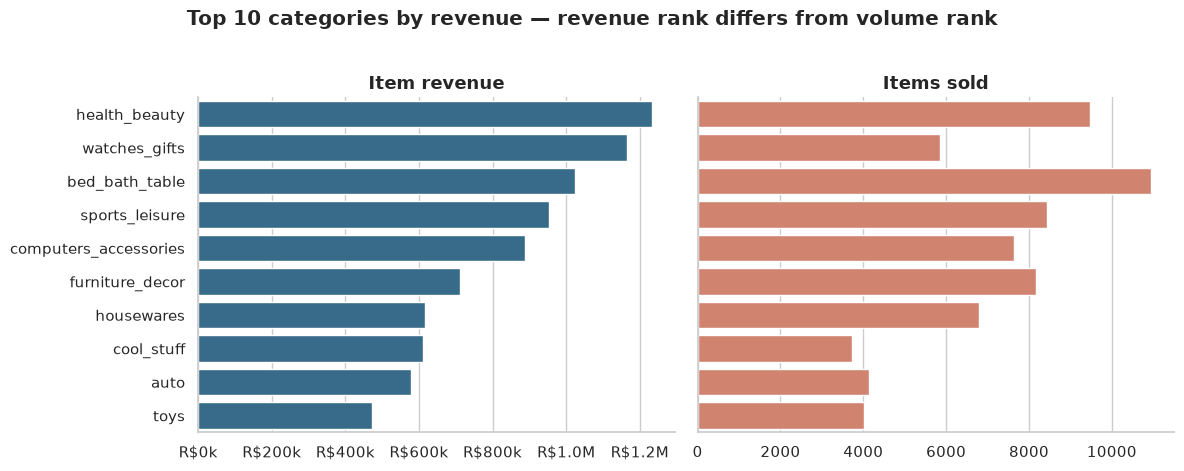

In [5]:
cat = olist.category_table(t)[["product_id","category"]]
it = t["items"].merge(d[["order_id"]], on="order_id").merge(cat, on="product_id", how="left")
c = it.groupby("category").agg(revenue=("price","sum"), items=("price","size"), avg_price=("price","mean")).sort_values("revenue", ascending=False)
c["share"] = c.revenue / c.revenue.sum(); c["cum_share"] = c.share.cumsum()
top = c.head(10)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
sns.barplot(x=top.revenue, y=top.index, ax=axes[0], color="#2a6f97"); axes[0].xaxis.set_major_formatter(BRL); axes[0].set_title("Item revenue"); axes[0].set_xlabel(""); axes[0].set_ylabel("")
sns.barplot(x=top["items"], y=top.index, ax=axes[1], color="#e07a5f"); axes[1].set_title("Items sold"); axes[1].set_xlabel("")
fig.suptitle("Top 10 categories by revenue — revenue rank differs from volume rank", fontweight="bold", y=1.02)
plt.tight_layout(); olist.save_fig(fig, "03_top_categories.png")
print(top[["revenue","items","avg_price","share"]].round(3).to_string())
print(f"\nTop 5 categories = {c.cum_share.iloc[4]:.1%} of revenue; top 10 = {c.cum_share.iloc[9]:.1%}; categories needed for 80%: {(c.cum_share<0.8).sum()+1} of {len(c)}")

**Interpretation.** Revenue is *spread* across many categories (top 10 ≈ 62%, not a single dominant line). `bed_bath_table` sells the most **units** but ranks 3rd by revenue; `watches_gifts` ranks 2nd by revenue on only ~5.9k items because of a ~R$199 average price. Volume ≠ value — merchandising should look at both.

## Chart 4 · Revenue concentration (Pareto)

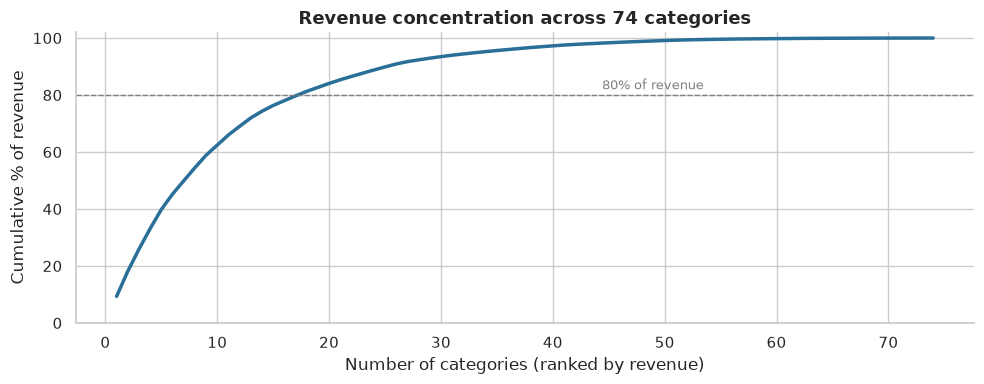

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(1, len(c)+1)
ax.plot(x, c.cum_share*100, color="#2a6f97", lw=2.5)
ax.axhline(80, color="gray", ls="--", lw=1); ax.text(len(c)*.6, 82, "80% of revenue", color="gray", fontsize=9)
ax.set_xlabel("Number of categories (ranked by revenue)"); ax.set_ylabel("Cumulative % of revenue"); ax.set_ylim(0, 102)
ax.set_title("Revenue concentration across 74 categories")
plt.tight_layout(); olist.save_fig(fig, "04_category_pareto.png")

## Chart 5 · Order value distribution (average order value & skew)

mean 137.04 | median 86.50 | p90 269 | p99 990 | max 13440 | skew 9.9
mean/median ratio 1.58; top 10% of orders = 41.0% of revenue
AOV incl. freight: 159.83


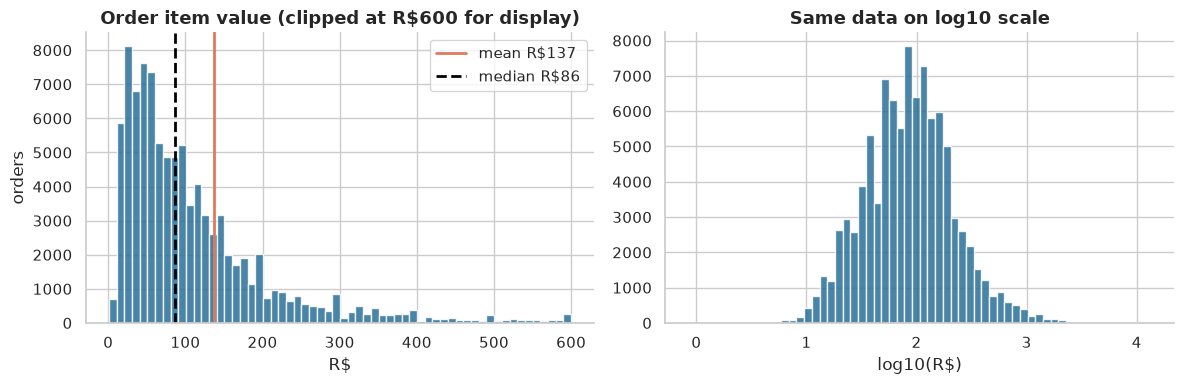

In [7]:
v = d.item_revenue
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(v[v<=600], bins=60, color="#2a6f97", alpha=.85)
axes[0].axvline(v.mean(), color="#e07a5f", lw=2, label=f"mean R${v.mean():.0f}"); axes[0].axvline(v.median(), color="black", lw=2, ls="--", label=f"median R${v.median():.0f}")
axes[0].legend(); axes[0].set_title("Order item value (clipped at R$600 for display)"); axes[0].set_xlabel("R$"); axes[0].set_ylabel("orders")
axes[1].hist(np.log10(v), bins=60, color="#2a6f97", alpha=.85); axes[1].set_title("Same data on log10 scale"); axes[1].set_xlabel("log10(R$)")
plt.tight_layout(); olist.save_fig(fig, "05_order_value_distribution.png")
print(f"mean {v.mean():.2f} | median {v.median():.2f} | p90 {v.quantile(.9):.0f} | p99 {v.quantile(.99):.0f} | max {v.max():.0f} | skew {v.skew():.1f}")
print(f"mean/median ratio {v.mean()/v.median():.2f}; top 10% of orders = {v.sort_values(ascending=False).head(int(len(v)*.1)).sum()/v.sum():.1%} of revenue")
print(f"AOV incl. freight: {d.total_value.mean():.2f}")

**Interpretation.** The distribution is strongly **right-skewed**: the mean (R$137) is ~58% above the median (R$87), so *the average overstates what a typical customer spends*. Report the **median** alongside AOV, and use log scales / rank-based tests for inference.

## Chart 6 · Geography — where the money is

SP 38.3% | SP+RJ+MG 63.4% | states: 27
AOV in SP: 125 vs median-state AOV 165


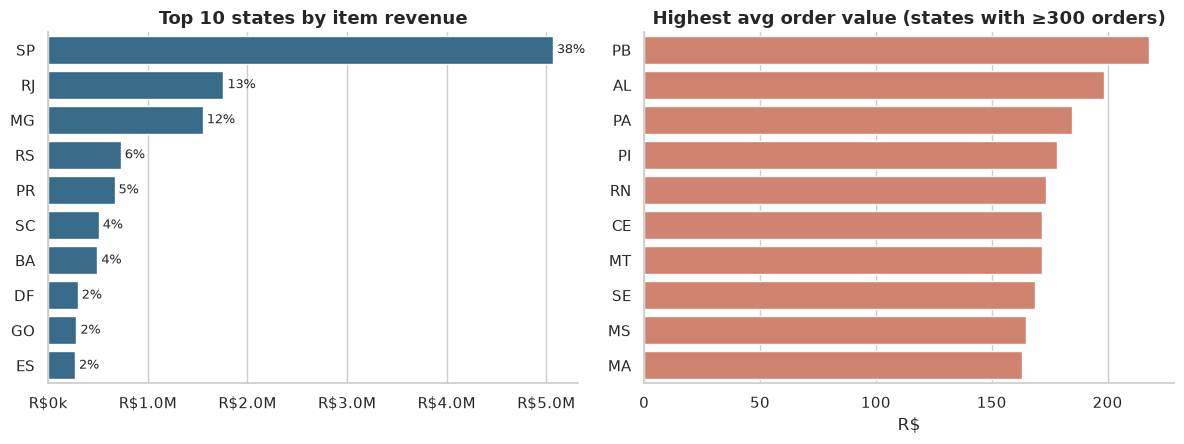

In [8]:
g = d.groupby("customer_state").agg(orders=("order_id","count"), revenue=("item_revenue","sum"), aov=("item_revenue","mean")).sort_values("revenue", ascending=False)
g["share"] = g.revenue / g.revenue.sum()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
sns.barplot(x=g.head(10).revenue, y=g.head(10).index, ax=axes[0], color="#2a6f97"); axes[0].xaxis.set_major_formatter(BRL)
axes[0].set_title("Top 10 states by item revenue"); axes[0].set_xlabel(""); axes[0].set_ylabel("")
for i, (st, r) in enumerate(g.head(10).iterrows()): axes[0].text(r.revenue, i, f" {r.share:.0%}", va="center", fontsize=9)
big = g[g.orders >= 300].sort_values("aov", ascending=False).head(10)
sns.barplot(x=big.aov, y=big.index, ax=axes[1], color="#e07a5f"); axes[1].set_title("Highest avg order value (states with ≥300 orders)"); axes[1].set_xlabel("R$"); axes[1].set_ylabel("")
plt.tight_layout(); olist.save_fig(fig, "06_state_revenue_aov.png")
print(f"SP {g.share['SP']:.1%} | SP+RJ+MG {g.share[['SP','RJ','MG']].sum():.1%} | states: {len(g)}")
print(f"AOV in SP: {g.aov['SP']:.0f} vs median-state AOV {g.aov.median():.0f}")

**Interpretation.** Demand is **geographically concentrated**: São Paulo alone is ~38% of revenue and SP+RJ+MG ≈ 63%. Smaller, remote states (PB, AL, PA, PI) have the *highest* order values but few orders — likely fewer, bigger, planned purchases, and higher freight (see SQL q16). *Hypothesis:* distance/freight cost is suppressing low-value orders outside the south-east.

## Chart 7 · Price distribution by category

                       median   mean      max
category                                     
health_beauty           80.00 130.00 3,124.00
watches_gifts          129.00 199.00 4,000.00
bed_bath_table          79.00  93.00 2,000.00
sports_leisure          78.00 113.00 4,059.00
computers_accessories   82.00 116.00 3,700.00
furniture_decor         65.00  87.00 1,899.00
housewares              60.00  91.00 6,735.00
cool_stuff             130.00 164.00 3,110.00


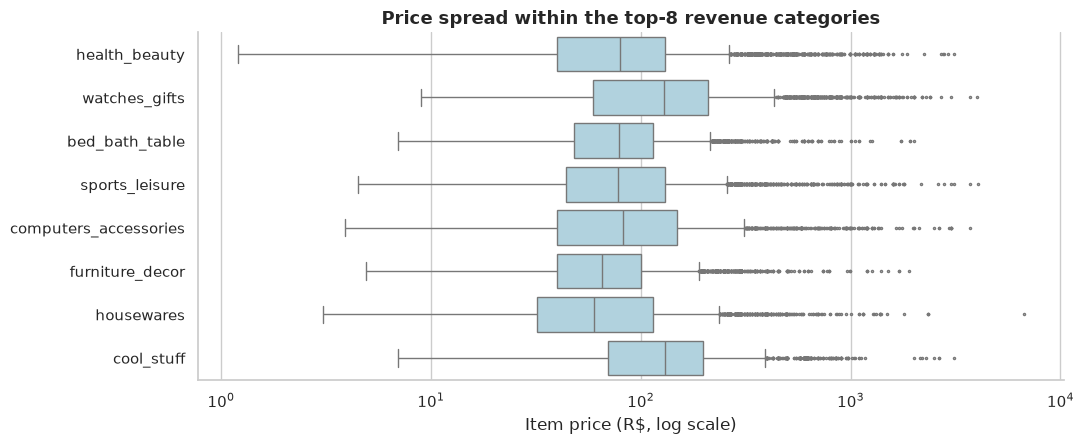

In [9]:
top8 = c.head(8).index
sub = it[it.category.isin(top8)]
fig, ax = plt.subplots(figsize=(11, 4.6))
sns.boxplot(data=sub, x="price", y="category", order=top8, ax=ax, color="#a9d6e5", fliersize=1.5)
ax.set_xscale("log"); ax.set_xlabel("Item price (R$, log scale)"); ax.set_ylabel("")
ax.set_title("Price spread within the top-8 revenue categories")
plt.tight_layout(); olist.save_fig(fig, "07_price_by_category.png")
print(sub.groupby("category").price.agg(["median","mean","max"]).loc[top8].round(0).to_string())

**Interpretation.** `watches_gifts` and `cool_stuff` sit at higher price points; `bed_bath_table` and `furniture_decor` are low-ticket, high-volume. Within-category price spread is wide (note the log axis) — averages hide a long tail of premium items.

## Chart 8 · When do customers buy?

dow
Mon   0.16
Tue   0.16
Wed   0.16
Thu   0.15
Fri   0.14
Sat   0.11
Sun   0.12
Share of orders 10:00-22:00: 75.7%


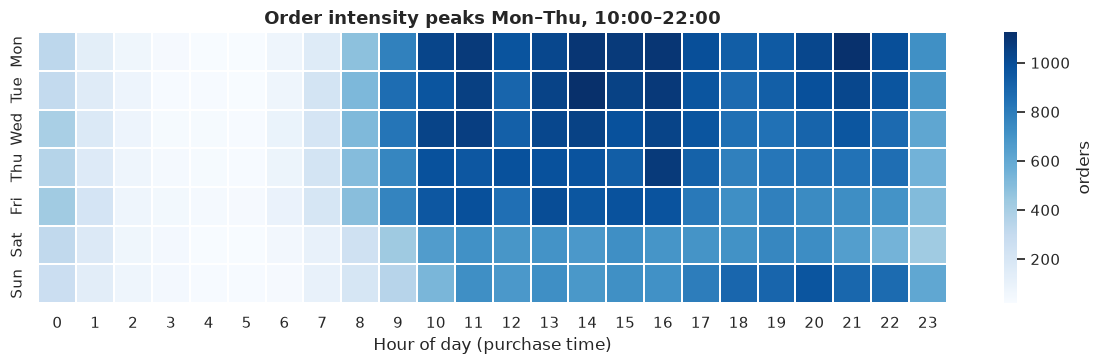

In [10]:
hh = f.copy()
hh["dow"] = hh.order_purchase_timestamp.dt.dayofweek; hh["hour"] = hh.order_purchase_timestamp.dt.hour
pivot = hh.pivot_table(index="dow", columns="hour", values="order_id", aggfunc="count")
pivot.index = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(pivot, cmap="Blues", ax=ax, cbar_kws={"label": "orders"}, linewidths=.3)
ax.set_xlabel("Hour of day (purchase time)"); ax.set_ylabel(""); ax.set_title("Order intensity peaks Mon–Thu, 10:00–22:00")
plt.tight_layout(); olist.save_fig(fig, "08_orders_weekday_hour_heatmap.png")
wk = hh.groupby("dow").size(); print((wk/wk.sum()).round(3).rename(dict(enumerate(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]))).to_string())
print(f"Share of orders 10:00-22:00: {hh.hour.between(10,21).mean():.1%}")

**Interpretation.** Orders cluster on weekdays and from late morning to evening; Saturday is the quietest day. Promotions / email sends and customer-support staffing could be aligned to this rhythm (a *testable* recommendation, not a proven effect).